<a href="https://colab.research.google.com/github/abrarjahinzihan/Salary_Prediction/blob/main/Salary_Prediction.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# 💰 Salary Prediction

**Goal:** Predict the expected salary of a candidate from a comprehensive profile (degree, experience, industry, job role, etc.).

**Requirements covered in this notebook**
1. Features such as degree qualification, years of experience, industry sector and job role
2. Feature scaling (StandardScaler vs MinMaxScaler vs RobustScaler)
3. Polynomial transformations (degree 1, 2, 3)
4. Feature correlation heatmaps
5. Use cases: helps employees estimate a fair market salary and supports HR teams in recruitment budgeting

**Dataset:** `job_salary_prediction_dataset.csv` (250,000 rows, 10 columns) – upload it to your Google Drive (`MyDrive`) and run the notebook top to bottom.

## 1. Setup & Load Data

In [ ]:
import warnings
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split, cross_val_score
from sklearn.preprocessing import (StandardScaler, MinMaxScaler, RobustScaler,
                                   OneHotEncoder, OrdinalEncoder, PolynomialFeatures)
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LinearRegression, Ridge
from sklearn.ensemble import RandomForestRegressor, HistGradientBoostingRegressor
from sklearn.inspection import permutation_importance
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

sns.set_theme(style="whitegrid", context="notebook")
RANDOM_STATE = 42

### Mount Google Drive
Put `job_salary_prediction_dataset.csv` in the root of **My Drive** (or edit `DATA_PATH` below to match your folder).

In [ ]:
try:
    from google.colab import drive
    drive.mount('/content/drive')
    DATA_PATH = '/content/drive/MyDrive/Untitled Folder/job_salary_prediction_dataset.csv'   # <- change if your file is in a subfolder
except ImportError:                       # running outside Colab
    DATA_PATH = 'job_salary_prediction_dataset.csv'

df = pd.read_csv(DATA_PATH)
print("Shape:", df.shape)
df.head()

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
Shape: (250000, 10)


,job_title,experience_years,education_level,skills_count,industry,company_size,location,remote_work,certifications,salary
0,AI Engineer,10,Bachelor,2,Healthcare,Medium,India,Hybrid,2,109413
1,Data Analyst,5,Bachelor,17,Telecom,Small,Australia,No,0,93764
2,Frontend Developer,18,PhD,4,Media,Medium,Singapore,No,1,148123
3,Business Analyst,19,PhD,13,Retail,Medium,Canada,Yes,0,189123
4,Product Manager,15,Bachelor,7,Manufacturing,Large,Sweden,Yes,0,165069


## 2. Data Overview & Quality Checks

In [ ]:
df.info()
print("\nMissing values:\n", df.isna().sum())
print("\nDuplicate rows:", df.duplicated().sum())
df.describe().T

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 250000 entries, 0 to 249999
Data columns (total 10 columns):
 #   Column            Non-Null Count   Dtype 
---  ------            --------------   ----- 
 0   job_title         250000 non-null  object
 1   experience_years  250000 non-null  int64 
 2   education_level   250000 non-null  object
 3   skills_count      250000 non-null  int64 
 4   industry          250000 non-null  object
 5   company_size      250000 non-null  object
 6   location          250000 non-null  object
 7   remote_work       250000 non-null  object
 8   certifications    250000 non-null  int64 
 9   salary            250000 non-null  int64 
dtypes: int64(4), object(6)
memory usage: 19.1+ MB

Missing values:
 job_title           0
experience_years    0
education_level     0
skills_count        0
industry            0
company_size        0
location            0
remote_work         0
certifications      0
salary              0
dtype: int64

Duplicate rows: 0


,count,mean,std,min,25%,50%,75%,max
experience_years,250000.0,10.005408,6.060602,0.0,5.0,10.0,15.0,20.0
skills_count,250000.0,9.997812,5.479288,1.0,5.0,10.0,15.0,19.0
certifications,250000.0,2.491928,1.706475,0.0,1.0,2.0,4.0,5.0
salary,250000.0,145718.080524,37407.952729,31867.0,119358.0,143453.0,169492.0,333046.0


In [ ]:
cat_cols = ["job_title", "education_level", "industry", "company_size", "location", "remote_work"]
for c in cat_cols:
    print(f"{c:16s} ({df[c].nunique()} unique): {sorted(df[c].unique())}")

job_title        (12 unique): ['AI Engineer', 'Backend Developer', 'Business Analyst', 'Cloud Engineer', 'Cybersecurity Analyst', 'Data Analyst', 'Data Scientist', 'DevOps Engineer', 'Frontend Developer', 'Machine Learning Engineer', 'Product Manager', 'Software Engineer']
education_level  (5 unique): ['Bachelor', 'Diploma', 'High School', 'Master', 'PhD']
industry         (10 unique): ['Consulting', 'Education', 'Finance', 'Government', 'Healthcare', 'Manufacturing', 'Media', 'Retail', 'Technology', 'Telecom']
company_size     (5 unique): ['Enterprise', 'Large', 'Medium', 'Small', 'Startup']
location         (10 unique): ['Australia', 'Canada', 'Germany', 'India', 'Netherlands', 'Remote', 'Singapore', 'Sweden', 'UK', 'USA']
remote_work      (3 unique): ['Hybrid', 'No', 'Yes']


## 3. Exploratory Data Analysis

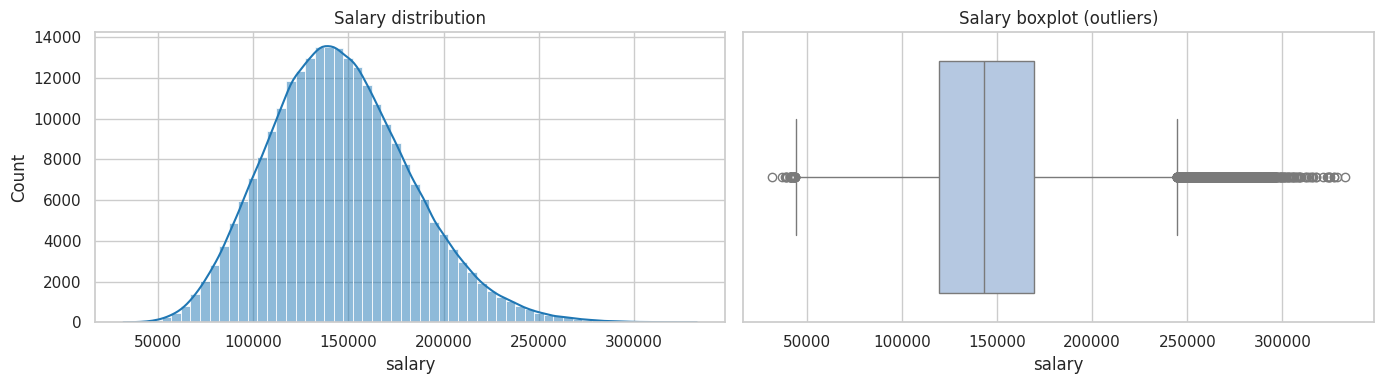

Skewness: 0.379


In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(14, 4))
sns.histplot(df["salary"], bins=60, kde=True, ax=axes[0], color="#1f77b4")
axes[0].set_title("Salary distribution")
sns.boxplot(x=df["salary"], ax=axes[1], color="#aec7e8")
axes[1].set_title("Salary boxplot (outliers)")
plt.tight_layout(); plt.show()
print("Skewness:", round(df['salary'].skew(), 3))

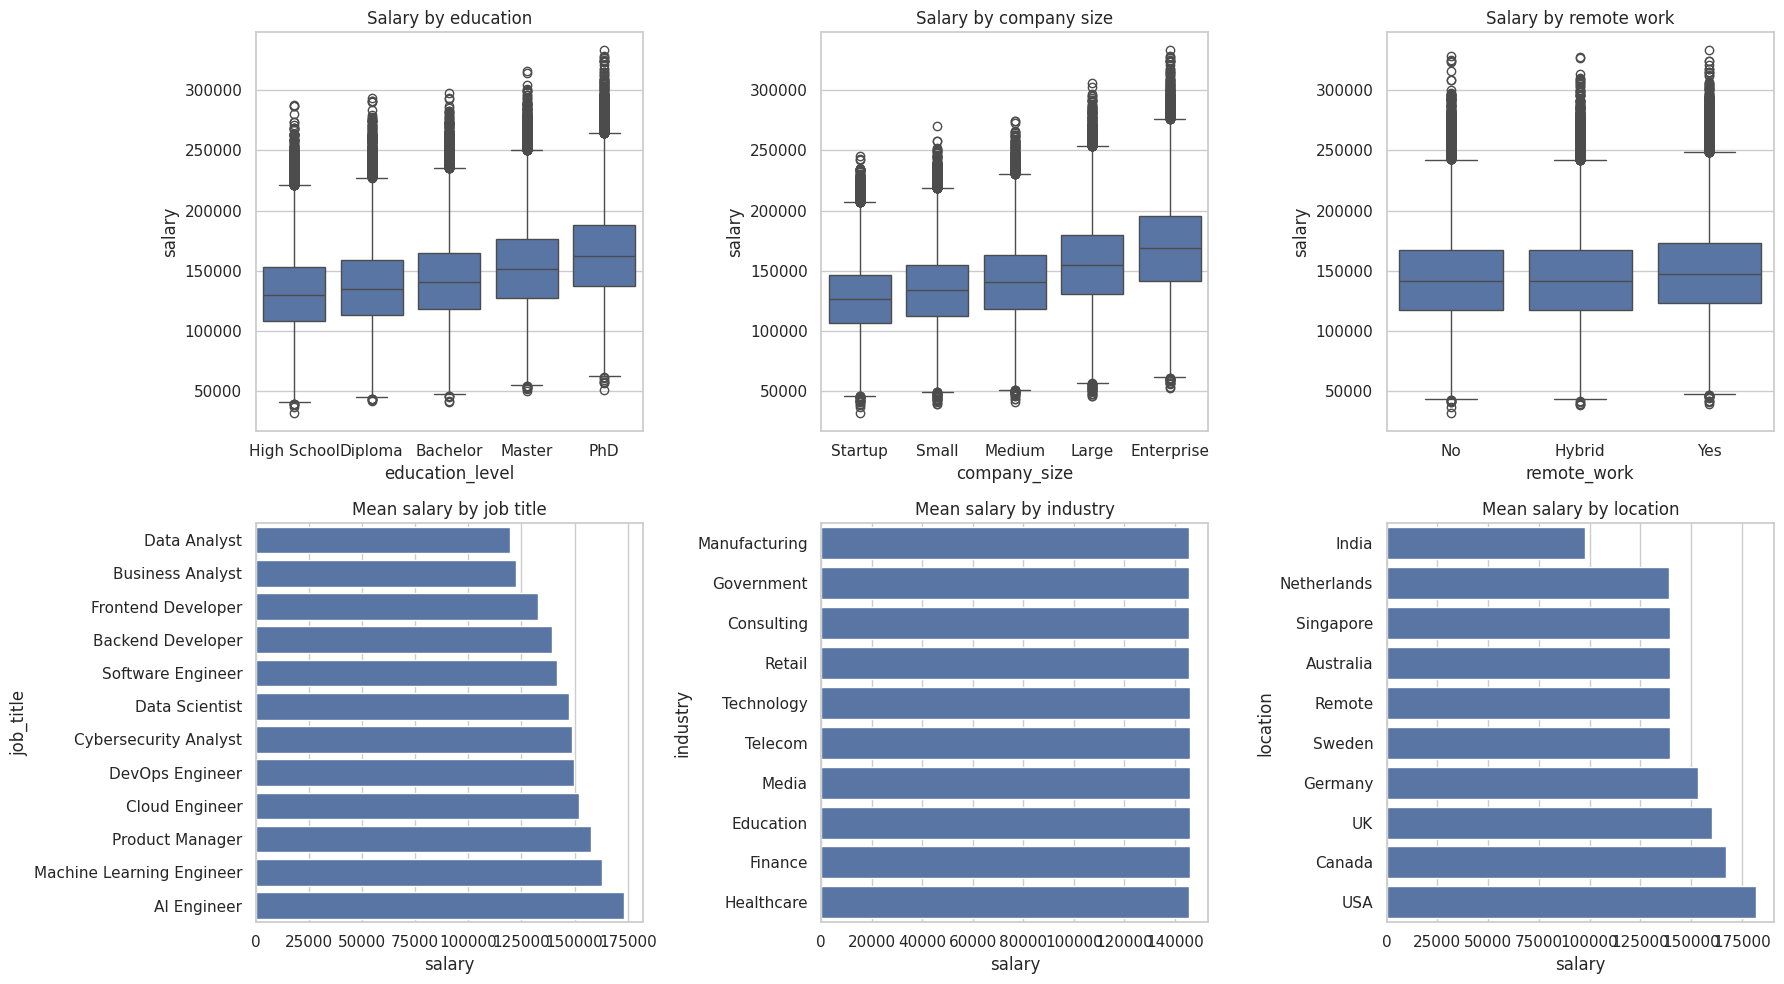

In [ ]:
edu_order  = ["High School", "Diploma", "Bachelor", "Master", "PhD"]
size_order = ["Startup", "Small", "Medium", "Large", "Enterprise"]
remote_order = ["No", "Hybrid", "Yes"]

fig, axes = plt.subplots(2, 3, figsize=(18, 10))
sns.boxplot(data=df, x="education_level", y="salary", order=edu_order, ax=axes[0,0]); axes[0,0].set_title("Salary by education")
sns.boxplot(data=df, x="company_size", y="salary", order=size_order, ax=axes[0,1]); axes[0,1].set_title("Salary by company size")
sns.boxplot(data=df, x="remote_work", y="salary", order=remote_order, ax=axes[0,2]); axes[0,2].set_title("Salary by remote work")

order = df.groupby("job_title")["salary"].median().sort_values().index
sns.barplot(data=df, y="job_title", x="salary", order=order, ax=axes[1,0], errorbar=None); axes[1,0].set_title("Mean salary by job title")
order = df.groupby("industry")["salary"].median().sort_values().index
sns.barplot(data=df, y="industry", x="salary", order=order, ax=axes[1,1], errorbar=None); axes[1,1].set_title("Mean salary by industry")
order = df.groupby("location")["salary"].median().sort_values().index
sns.barplot(data=df, y="location", x="salary", order=order, ax=axes[1,2], errorbar=None); axes[1,2].set_title("Mean salary by location")
plt.tight_layout(); plt.show()

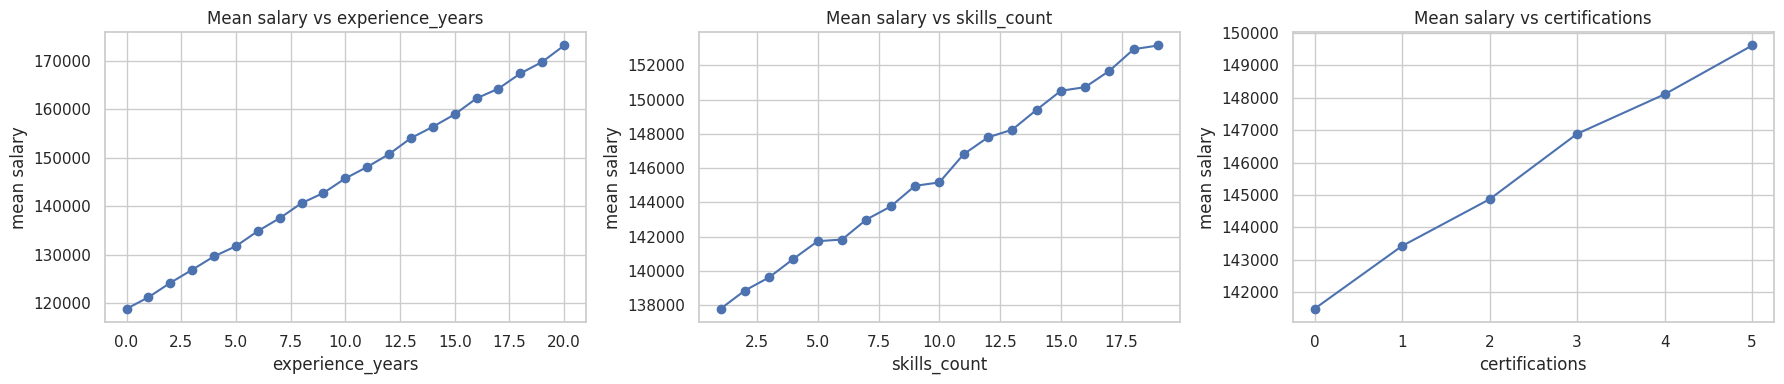

In [ ]:
fig, axes = plt.subplots(1, 3, figsize=(18, 4))
for ax, col in zip(axes, ["experience_years", "skills_count", "certifications"]):
    df.groupby(col)["salary"].mean().plot(marker="o", ax=ax)
    ax.set_title(f"Mean salary vs {col}"); ax.set_ylabel("mean salary")
plt.tight_layout(); plt.show()

## 4. Feature Correlation Heatmaps
**Heatmap A** uses only the raw numeric columns.
**Heatmap B** converts ordered categories (education, company size, remote work) to ordinal numbers and the nominal categories (job title, industry, location) to their *mean salary* so that every feature can be compared with salary. *(Target encoding here is for exploration only – the models below use proper one‑hot encoding inside a pipeline, so there is no leakage.)*

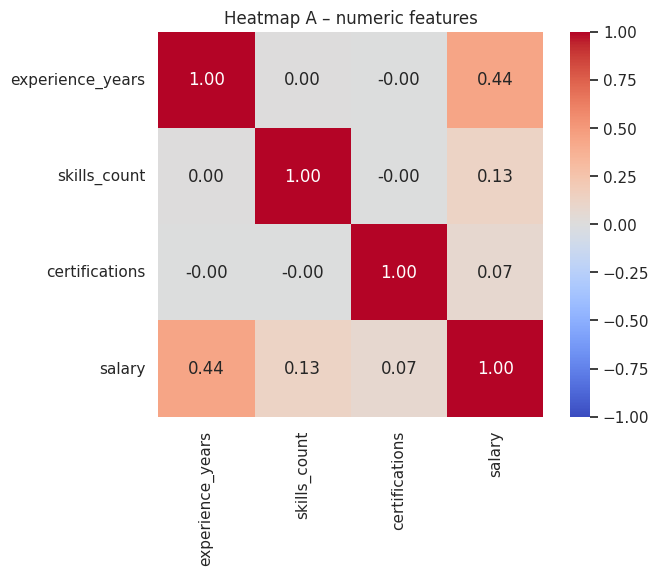

In [ ]:
num_cols = ["experience_years", "skills_count", "certifications", "salary"]
plt.figure(figsize=(7, 5))
sns.heatmap(df[num_cols].corr(), annot=True, fmt=".2f", cmap="coolwarm", vmin=-1, vmax=1, square=True)
plt.title("Heatmap A – numeric features")
plt.show()

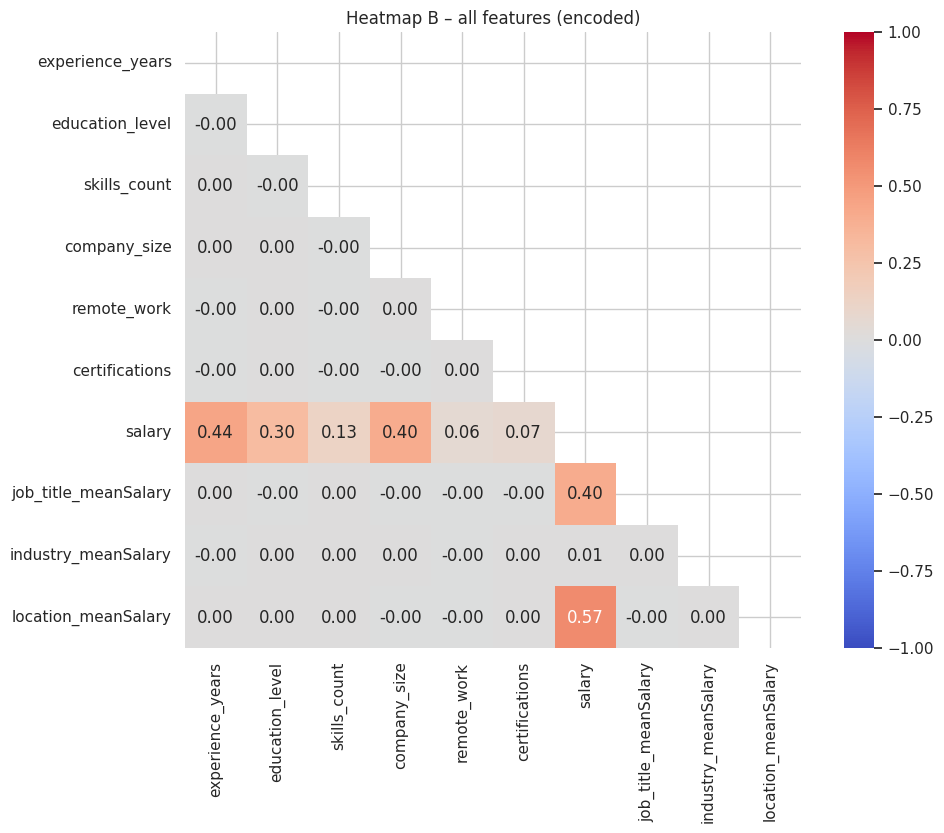

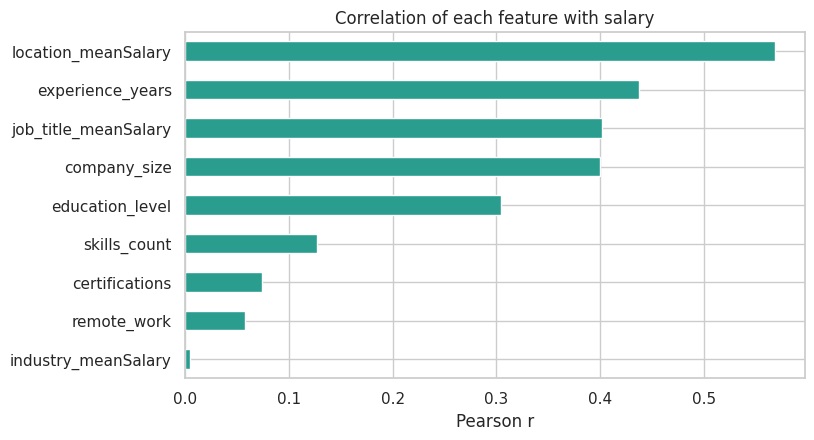

In [ ]:
enc = df.copy()
enc["education_level"] = enc["education_level"].map({k: i for i, k in enumerate(edu_order)})
enc["company_size"]    = enc["company_size"].map({k: i for i, k in enumerate(size_order)})
enc["remote_work"]     = enc["remote_work"].map({k: i for i, k in enumerate(remote_order)})
for c in ["job_title", "industry", "location"]:
    enc[c + "_meanSalary"] = enc[c].map(df.groupby(c)["salary"].mean())
enc = enc.drop(columns=["job_title", "industry", "location"])

corr = enc.corr()
plt.figure(figsize=(11, 8))
mask = np.triu(np.ones_like(corr, dtype=bool))
sns.heatmap(corr, mask=mask, annot=True, fmt=".2f", cmap="coolwarm", vmin=-1, vmax=1, square=True)
plt.title("Heatmap B – all features (encoded)")
plt.show()

plt.figure(figsize=(8, 4.5))
corr["salary"].drop("salary").sort_values().plot(kind="barh", color="#2a9d8f")
plt.title("Correlation of each feature with salary"); plt.xlabel("Pearson r")
plt.show()

## 5. Preprocessing: Train/Test Split & Feature Groups
- **Ordinal features** (education, company size, remote work) → `OrdinalEncoder` with a meaningful order
- **Nominal features** (job title, industry, location) → `OneHotEncoder`
- **Numeric features** (experience, skills, certifications) → scaled (and later expanded with polynomial terms)

The split is done **before** any fitting so the scalers/encoders only learn from training data.

In [ ]:
X = df.drop(columns="salary")
y = df["salary"]
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=RANDOM_STATE)
print(X_train.shape, X_test.shape)

numeric_features = ["experience_years", "skills_count", "certifications"]
ordinal_features = ["education_level", "company_size", "remote_work"]
nominal_features = ["job_title", "industry", "location"]
ordinal_categories = [edu_order, size_order, remote_order]

(200000, 9) (50000, 9)


## 6. Feature Scaling
Scaling matters for linear/regularised models and keeps polynomial terms numerically stable. Below we compare three scalers on the numeric features, then see how each affects a Ridge model.

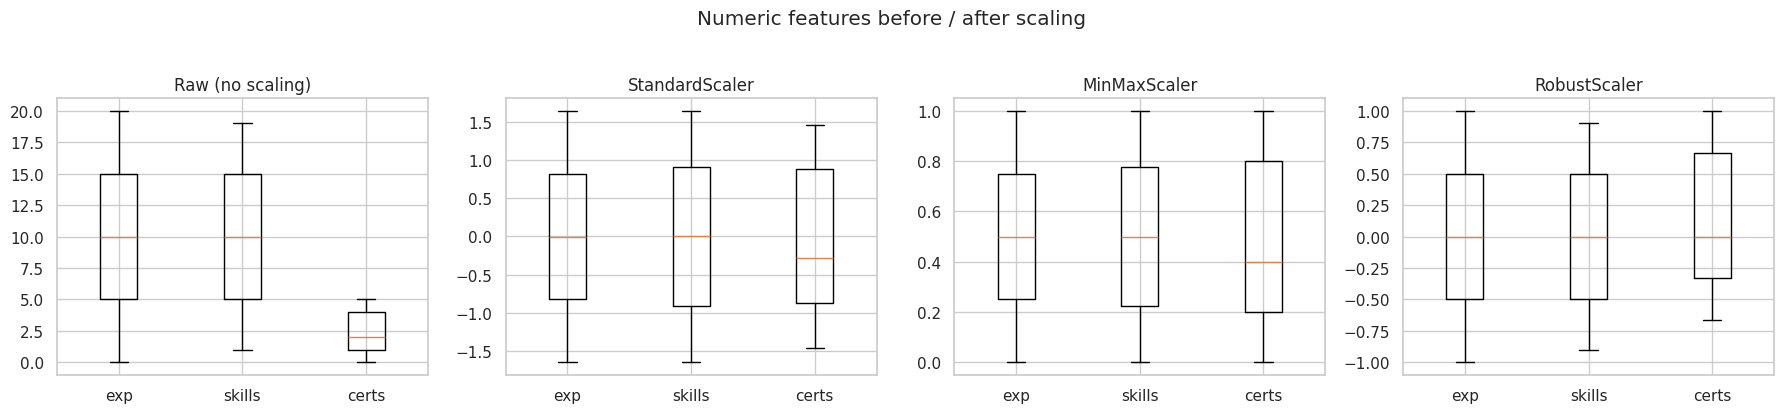

      experience_years  skills_count  certifications
mean              -0.0           0.0            -0.0
std                1.0           1.0             1.0


In [ ]:
scalers = {"Raw (no scaling)": None, "StandardScaler": StandardScaler(),
           "MinMaxScaler": MinMaxScaler(), "RobustScaler": RobustScaler()}

fig, axes = plt.subplots(1, 4, figsize=(18, 4), sharey=False)
for ax, (name, sc) in zip(axes, scalers.items()):
    data = X_train[numeric_features].values if sc is None else sc.fit_transform(X_train[numeric_features])
    ax.boxplot(data)
    ax.set_xticklabels(["exp", "skills", "certs"])
    ax.set_title(name)
plt.suptitle("Numeric features before / after scaling", y=1.03)
plt.tight_layout(); plt.show()

print(pd.DataFrame(StandardScaler().fit_transform(X_train[numeric_features]), columns=numeric_features)
        .describe().loc[["mean", "std"]].round(3))

In [ ]:
def build_preprocessor(scaler=None, degree=1):
    num_steps = [("scale", scaler)] if scaler is not None else []
    # polynomial expansion over numeric + ordinal features (interactions + powers)
    num_ord_steps = num_steps + ([("poly", PolynomialFeatures(degree=degree, include_bias=False))] if degree > 1 else [])
    return ColumnTransformer([
        ("numord", Pipeline([("ord", ColumnTransformer([
                                ("num", "passthrough", numeric_features),
                                ("ord", OrdinalEncoder(categories=ordinal_categories), ordinal_features)]))]
                            + num_ord_steps), numeric_features + ordinal_features),
        ("nom", OneHotEncoder(handle_unknown="ignore"), nominal_features),
    ])

def evaluate(model, name):
    pred = model.predict(X_test)
    return {"Model": name,
            "MAE": mean_absolute_error(y_test, pred),
            "RMSE": np.sqrt(mean_squared_error(y_test, pred)),
            "R2": r2_score(y_test, pred)}

# effect of scaler on Ridge (degree 1)
rows = []
for name, sc in scalers.items():
    pipe = Pipeline([("prep", build_preprocessor(sc, 1)), ("model", Ridge(alpha=1.0))]).fit(X_train, y_train)
    rows.append(evaluate(pipe, f"Ridge + {name}"))
scaling_results = pd.DataFrame(rows).set_index("Model").round(4)
scaling_results

,MAE,RMSE,R2
Model,,,
Ridge + Raw (no scaling),6154.3569,7987.4651,0.9541
Ridge + StandardScaler,6154.5892,7987.4838,0.9541
Ridge + MinMaxScaler,6154.5690,7987.4802,0.9541
Ridge + RobustScaler,6154.5534,7987.4794,0.9541


*Scaling barely changes plain linear-model accuracy (the fit is scale-invariant apart from the Ridge penalty), but it matters once we add polynomial terms and regularisation – so **StandardScaler** is used from here on.*

## 7. Polynomial Transformations
We expand the numeric + ordinal features with polynomial and interaction terms (degree 1 = plain linear, 2 = squares & pairwise interactions, 3 = cubic terms) and watch the effect on error.

,MAE,RMSE,R2,Degree,Train R2
Model,,,,,
Ridge poly degree 1,6154.5892,7987.4838,0.9541,1,0.9543
Ridge poly degree 2,5276.0894,6881.9267,0.9659,2,0.9660
Ridge poly degree 3,5269.4098,6873.0710,0.9660,3,0.9662


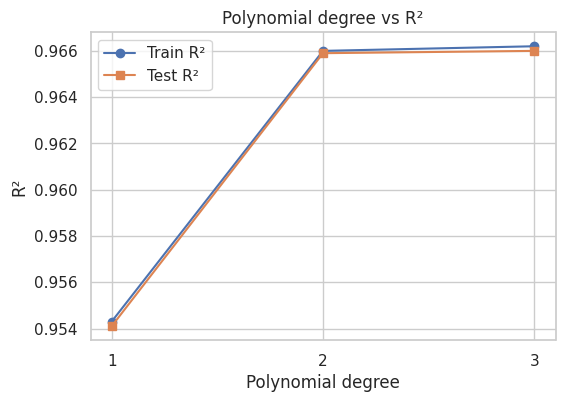

In [ ]:
poly_rows, poly_models = [], {}
for d in [1, 2, 3]:
    pipe = Pipeline([("prep", build_preprocessor(StandardScaler(), d)),
                     ("model", Ridge(alpha=1.0))]).fit(X_train, y_train)
    poly_models[d] = pipe
    r = evaluate(pipe, f"Ridge poly degree {d}"); r["Degree"] = d
    r["Train R2"] = r2_score(y_train, pipe.predict(X_train))
    poly_rows.append(r)
poly_results = pd.DataFrame(poly_rows).set_index("Model").round(4)
display(poly_results)

fig, ax = plt.subplots(figsize=(6, 4))
ax.plot(poly_results["Degree"], poly_results["Train R2"], marker="o", label="Train R²")
ax.plot(poly_results["Degree"], poly_results["R2"], marker="s", label="Test R²")
ax.set_xticks([1, 2, 3]); ax.set_xlabel("Polynomial degree"); ax.set_ylabel("R²"); ax.legend()
ax.set_title("Polynomial degree vs R²")
plt.show()

## 8. Model Training & Comparison
We compare the regularised polynomial linear model with two tree-based ensembles (which capture non-linearity & interactions automatically).

In [ ]:
tree_prep = ColumnTransformer([
    ("ord", OrdinalEncoder(categories=ordinal_categories), ordinal_features),
    ("nom", OneHotEncoder(handle_unknown="ignore", sparse_output=False), nominal_features),
    ("num", "passthrough", numeric_features)])

models = {
    "Linear Regression (scaled)": Pipeline([("prep", build_preprocessor(StandardScaler(), 1)), ("model", LinearRegression())]),
    "Ridge + Poly (deg 2)":       poly_models[2],
    "Ridge + Poly (deg 3)":       poly_models[3],
    "Random Forest":              Pipeline([("prep", tree_prep),
                                            ("model", RandomForestRegressor(n_estimators=60, max_depth=14, min_samples_leaf=5,
                                                                            n_jobs=-1, random_state=RANDOM_STATE))]),
    "Gradient Boosting (HistGB)": Pipeline([("prep", tree_prep),
                                            ("model", HistGradientBoostingRegressor(max_iter=300, learning_rate=0.1,
                                                                                    random_state=RANDOM_STATE))]),
}

results = []
for name, m in models.items():
    if name not in ("Ridge + Poly (deg 2)", "Ridge + Poly (deg 3)"):
        m.fit(X_train, y_train)
    results.append(evaluate(m, name))
results = pd.DataFrame(results).set_index("Model").sort_values("R2", ascending=False)
results.round(4)

,MAE,RMSE,R2
Model,,,
Gradient Boosting (HistGB),4208.5519,5276.7418,0.9800
Ridge + Poly (deg 3),5269.4098,6873.0710,0.9660
Ridge + Poly (deg 2),5276.0894,6881.9267,0.9659
Linear Regression (scaled),6154.6079,7987.5043,0.9541
Random Forest,7842.2866,9999.1256,0.9281


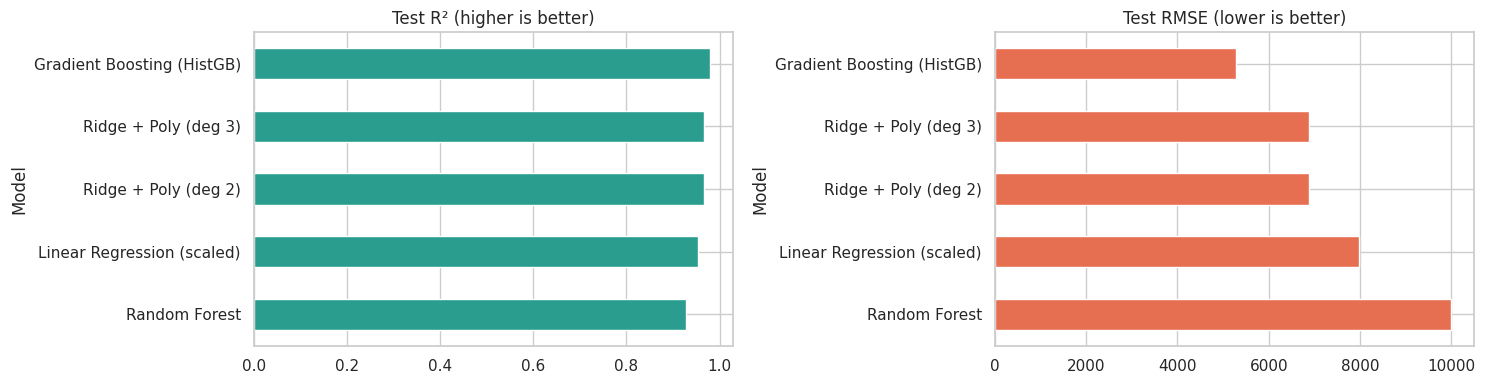

Best model: Gradient Boosting (HistGB)


In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(15, 4))
results["R2"].sort_values().plot(kind="barh", ax=axes[0], color="#2a9d8f"); axes[0].set_title("Test R² (higher is better)")
results["RMSE"].sort_values(ascending=False).plot(kind="barh", ax=axes[1], color="#e76f51"); axes[1].set_title("Test RMSE (lower is better)")
plt.tight_layout(); plt.show()

best_name = results.index[0]
best_model = models[best_name]
print("Best model:", best_name)

### 8.1 Cross-validation of the best model (5-fold, on a 50k sample for speed)

In [ ]:
sample = df.sample(50000, random_state=RANDOM_STATE)
cv = cross_val_score(best_model, sample.drop(columns="salary"), sample["salary"], cv=5, scoring="r2", n_jobs=1)
print("CV R² per fold:", cv.round(4), "| mean = %.4f ± %.4f" % (cv.mean(), cv.std()))

CV R² per fold: [0.9798 0.9788 0.9784 0.9782 0.9791] | mean = 0.9789 ± 0.0006


## 9. Diagnostics of the Best Model

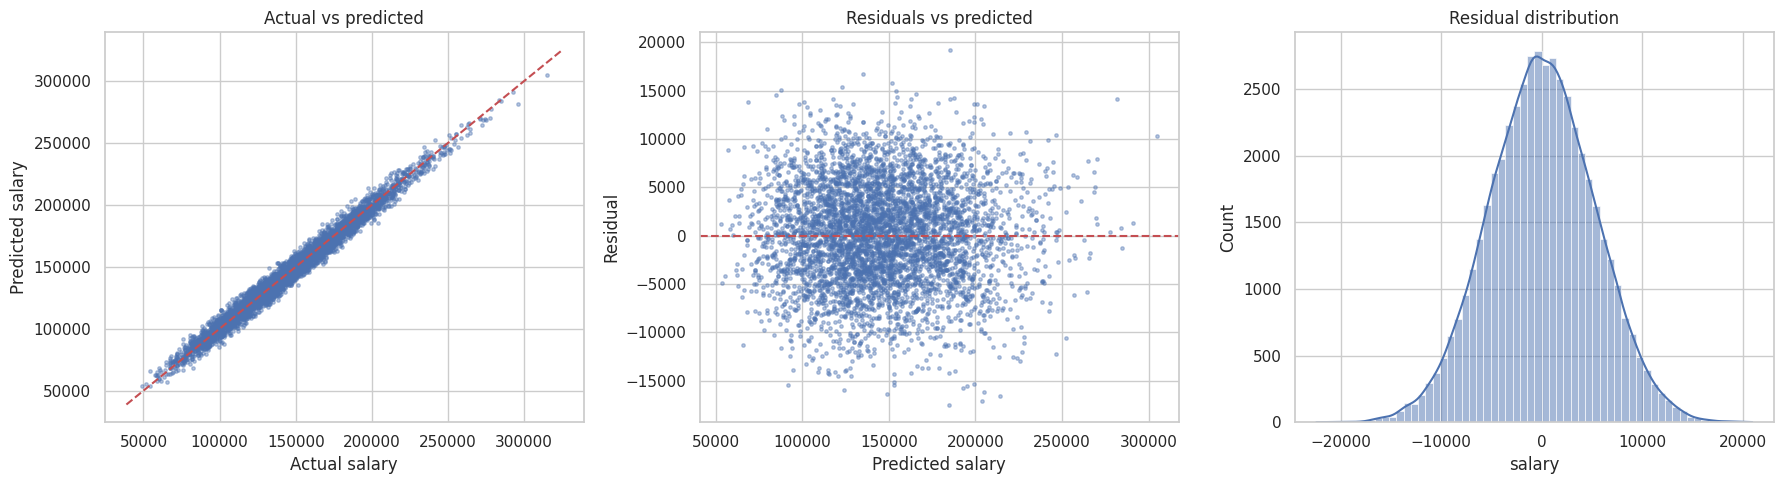

In [ ]:
pred = best_model.predict(X_test)
resid = y_test - pred
idx = np.random.RandomState(0).choice(len(y_test), 5000, replace=False)

fig, axes = plt.subplots(1, 3, figsize=(18, 5))
axes[0].scatter(y_test.values[idx], pred[idx], s=6, alpha=0.4)
lims = [y_test.min(), y_test.max()]; axes[0].plot(lims, lims, "r--")
axes[0].set_xlabel("Actual salary"); axes[0].set_ylabel("Predicted salary"); axes[0].set_title("Actual vs predicted")
axes[1].scatter(pred[idx], resid.values[idx], s=6, alpha=0.4); axes[1].axhline(0, color="r", ls="--")
axes[1].set_xlabel("Predicted salary"); axes[1].set_ylabel("Residual"); axes[1].set_title("Residuals vs predicted")
sns.histplot(resid, bins=60, kde=True, ax=axes[2]); axes[2].set_title("Residual distribution")
plt.tight_layout(); plt.show()

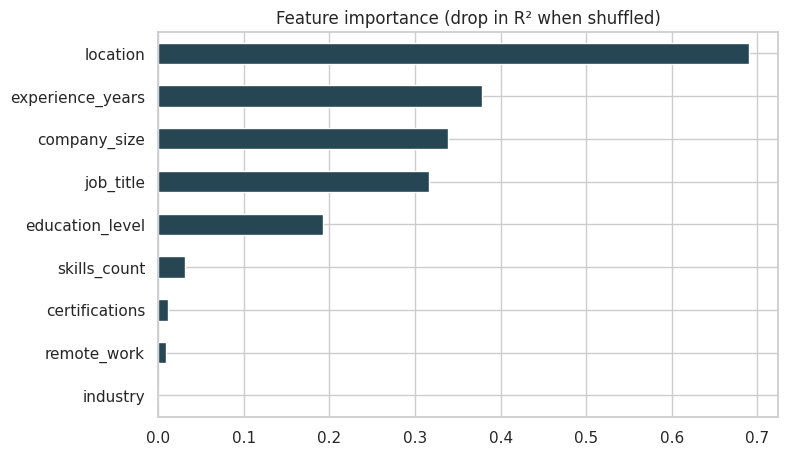

In [ ]:
# Permutation importance on the raw input columns (works with any pipeline)
Xs = X_test.sample(5000, random_state=1); ys = y_test.loc[Xs.index]
imp = permutation_importance(best_model, Xs, ys, n_repeats=5, random_state=RANDOM_STATE, scoring="r2", n_jobs=1)
imp_df = pd.Series(imp.importances_mean, index=X.columns).sort_values()
imp_df.plot(kind="barh", figsize=(8, 5), color="#264653")
plt.title("Feature importance (drop in R² when shuffled)"); plt.show()

## 10. Use It: Salary Estimator
Employees can estimate a fair market salary for their profile, and HR teams can budget for a new hire by changing the inputs.

In [ ]:
def predict_salary(job_title, experience_years, education_level, skills_count,
                   industry, company_size, location, remote_work, certifications, model=best_model):
    row = pd.DataFrame([{
        "job_title": job_title, "experience_years": experience_years, "education_level": education_level,
        "skills_count": skills_count, "industry": industry, "company_size": company_size,
        "location": location, "remote_work": remote_work, "certifications": certifications}])
    return float(model.predict(row)[0])

example = dict(job_title="Data Scientist", experience_years=5, education_level="Master", skills_count=12,
               industry="Technology", company_size="Large", location="USA", remote_work="Hybrid", certifications=2)
print(f"Estimated salary: ${predict_salary(**example):,.0f}")

Estimated salary: $188,369


In [ ]:
# HR budgeting: salary range for the same role across experience levels
rows = [{"experience_years": e, "estimated_salary": predict_salary(**{**example, "experience_years": e})} for e in range(0, 21, 5)]
pd.DataFrame(rows).style.format({"estimated_salary": "${:,.0f}"})

,experience_years,estimated_salary
0,0,"$167,581"
1,5,"$188,369"
2,10,"$203,947"
3,15,"$225,332"
4,20,"$243,058"


In [ ]:
# Employee view: how much do degree and certifications move the estimate?
rows = [{"education": e, "estimated_salary": predict_salary(**{**example, "education_level": e})} for e in edu_order]
pd.DataFrame(rows).style.format({"estimated_salary": "${:,.0f}"})

,education,estimated_salary
0,High School,"$158,800"
1,Diploma,"$165,751"
2,Bachelor,"$175,926"
3,Master,"$188,369"
4,PhD,"$199,430"
